# 01 - Sanity check: five objects across the May 2024 storm

Goal: check that the orbit math works before scaling up.

- **Control:** LAGEOS-1 (~5,900 km). Essentially no air drag there, so the storm should do nothing.
- **~800 km:** Starlette and Stella. Thin air, so we expect a small effect.
- **~450-550 km:** two passive rocket bodies. We expect a clear extra drop in semi-major axis right after the May 10-11 storm.

Outcome: Brouwer mean semi-major axis from python-sgp4 (`no_kozai`). BSTAR is not used.
All logic lives in `src/`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.spacetrack_io import download_tle_history, find_candidates
from src.omni_io import load_omni2
from src.orbit import tles_to_frame, drop_duplicate_epochs, decay_rates, mean_decay_before_after
from src.plots import plot_object_with_storm

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

STORM_ONSET = pd.Timestamp("2024-05-10 17:00")   # main phase of the May 2024 G5 storm
WINDOW = (pd.Timestamp("2024-04-15"), pd.Timestamp("2024-06-15"))

## 1. Choose two passive low objects

We ask Space-Track for rocket bodies and debris whose orbit on **14 Apr 2024** (before the storm) was
near-circular (e < 0.01) with perigee > 450 km and apogee < 550 km. We use the orbit at that date, not today's.
From the list we pick two **large** rocket bodies (large radar cross-section, so well tracked), that have been
passive for a long time and that differ in altitude and inclination.

In [2]:
cand = pd.DataFrame(find_candidates("2024-04-14"))
for c in ["ECCENTRICITY", "INCLINATION", "PERIAPSIS", "APOAPSIS"]:
    cand[c] = cand[c].astype(float)
cand = cand.drop_duplicates("NORAD_CAT_ID", keep="last")
print(f"{len(cand)} candidates:", cand["OBJECT_TYPE"].value_counts().to_dict())

CHOSEN = [10114, 41341]
cols = ["NORAD_CAT_ID", "OBJECT_NAME", "OBJECT_TYPE", "ECCENTRICITY", "INCLINATION",
        "PERIAPSIS", "APOAPSIS", "RCS_SIZE", "LAUNCH_DATE"]
chosen = cand[cand["NORAD_CAT_ID"].astype(int).isin(CHOSEN)][cols]
display(chosen)
for _, r in chosen.iterrows():
    print(f"{r.OBJECT_NAME} ({r.NORAD_CAT_ID}): {r.OBJECT_TYPE.lower()} launched {r.LAUNCH_DATE}, "
          f"e = {r.ECCENTRICITY:.4f}, altitude {r.PERIAPSIS:.0f}-{r.APOAPSIS:.0f} km, "
          f"inclination {r.INCLINATION:.1f} deg, RCS {r.RCS_SIZE}")
print("Why these two: both near-circular and inside 450-550 km; large and long-passive (no manoeuvres);")
print("one polar (97.5 deg, ~486 km) and one low-inclination (30.6 deg, ~515 km), so they sample different")
print("latitudes and altitudes of the storm heating.")

106 candidates: {'DEBRIS': 66, 'ROCKET BODY': 40}


,NORAD_CAT_ID,OBJECT_NAME,OBJECT_TYPE,ECCENTRICITY,INCLINATION,PERIAPSIS,APOAPSIS,RCS_SIZE,LAUNCH_DATE
23,10114,SL-3 R/B,ROCKET BODY,0.001009,97.5000,479.064,492.911,LARGE,1977-06-29
159,41341,H-2A R/B,ROCKET BODY,0.001466,30.6229,505.143,525.359,LARGE,2016-02-17


SL-3 R/B (10114): rocket body launched 1977-06-29, e = 0.0010, altitude 479-493 km, inclination 97.5 deg, RCS LARGE
H-2A R/B (41341): rocket body launched 2016-02-17, e = 0.0015, altitude 505-525 km, inclination 30.6 deg, RCS LARGE
Why these two: both near-circular and inside 450-550 km; large and long-passive (no manoeuvres);
one polar (97.5 deg, ~486 km) and one low-inclination (30.6 deg, ~515 km), so they sample different
latitudes and altitudes of the storm heating.


## 2. Download TLEs and space weather

In [3]:
OBJECTS = {8820: "LAGEOS-1 (control, ~5,900 km)",
           7646: "Starlette (~800-1,100 km)",
           22824: "Stella (~800 km)",
           10114: "SL-3 R/B (~486 km)",
           41341: "H-2A R/B (~515 km)"}

# A little margin around the plotting window so the first/last intervals are complete
records = download_tle_history(list(OBJECTS), "2024-04-01", "2024-06-30", out_name="tle_sanity_2024.json")
raw = tles_to_frame(records)
tles = drop_duplicate_epochs(raw)
rates = decay_rates(tles)

summary = tles.groupby("norad_id").agg(n_tles=("epoch", "size"), mean_a_km=("a_km", "mean"),
                                       mean_ecc=("ecc", "mean"), incl_deg=("incl_deg", "mean"))
summary["duplicates_removed"] = raw.groupby("norad_id").size() - summary["n_tles"]
summary["min_dt_hours"] = rates.groupby("norad_id")["dt_days"].min() * 24
summary.insert(0, "name", summary.index.map(OBJECTS))
summary

,name,n_tles,mean_a_km,mean_ecc,incl_deg,duplicates_removed,min_dt_hours
norad_id,,,,,,,
7646,"Starlette (~800-1,100 km)",225,7333.781173,0.020569,49.823974,16,1.735002
8820,"LAGEOS-1 (control, ~5,900 km)",120,12271.187327,0.004428,109.851086,25,3.339254
10114,SL-3 R/B (~486 km),224,6862.002301,0.001105,97.504642,5,1.571522
22824,Stella (~800 km),228,7178.494639,0.000612,98.881643,2,1.220848
41341,H-2A R/B (~515 km),171,6890.532856,0.001369,30.623466,33,1.577141


In [4]:
omni = load_omni2(2024)
storm = omni.loc["2024-05-10":"2024-05-12"]
print(f"May 10-12: min Dst = {storm.dst.min():.0f} nT at {storm.dst.idxmin()}, max ap = {storm.ap.max():.0f} nT")
print(f"F10.7 in the window: {omni.loc[WINDOW[0]:WINDOW[1], 'f107'].min():.0f}-{omni.loc[WINDOW[0]:WINDOW[1], 'f107'].max():.0f} sfu")

May 10-12: min Dst = -406 nT at 2024-05-11 02:00:00, max ap = 400 nT
F10.7 in the window: 132-238 sfu


## 3. Plots: a(t), decay rate, Dst and ap per object

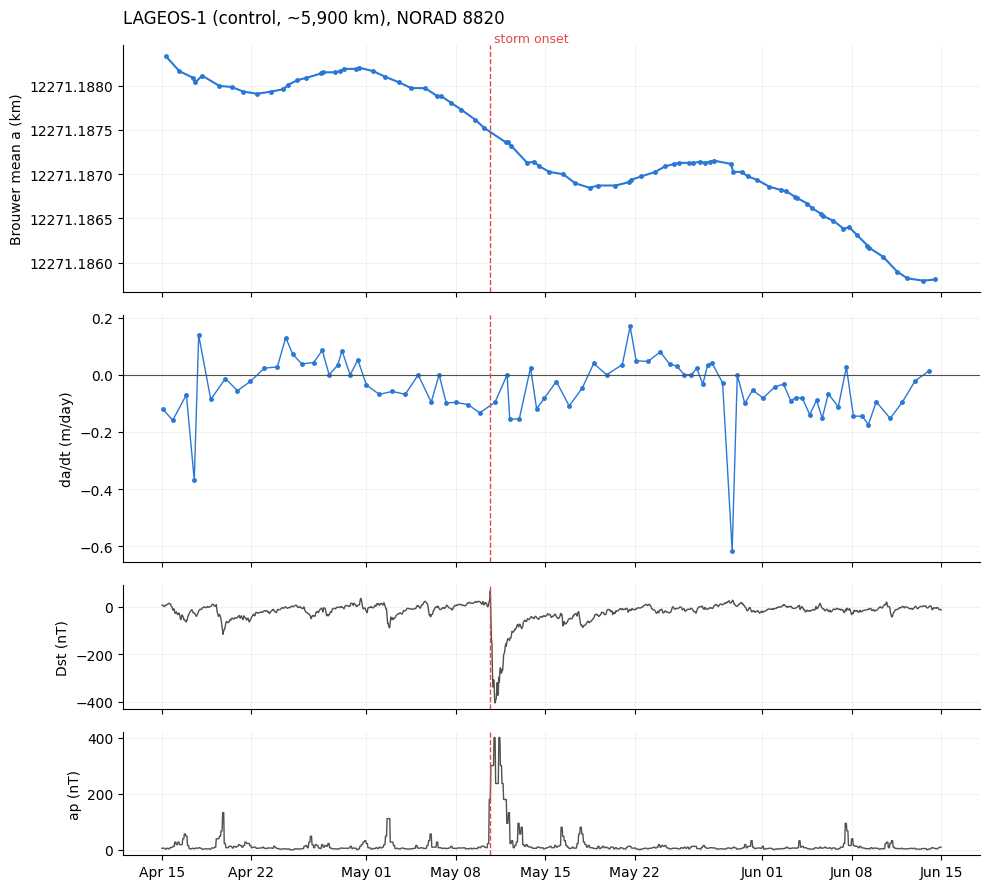

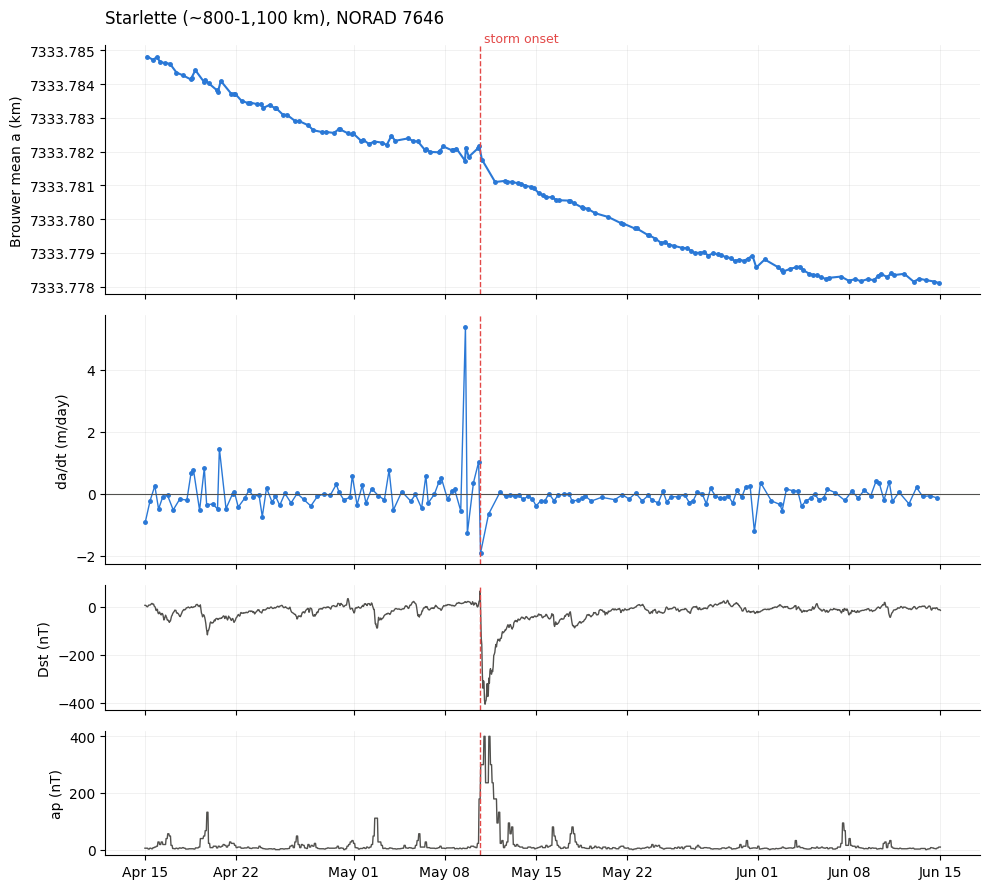

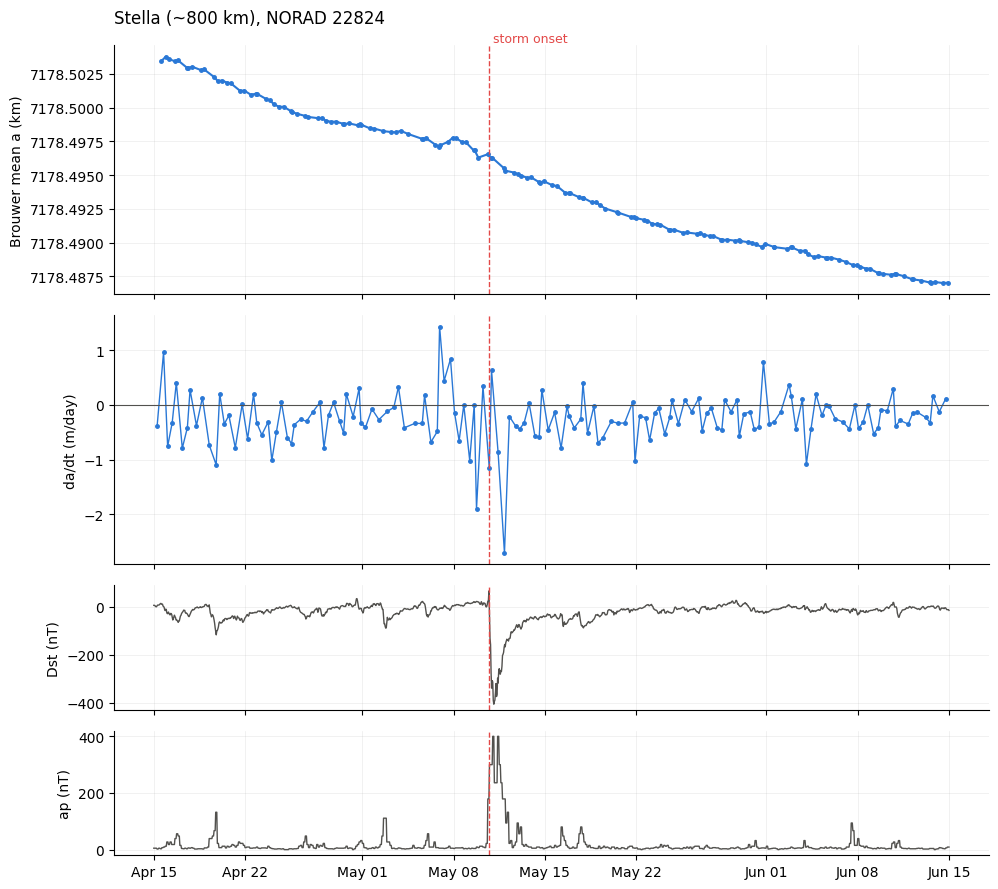

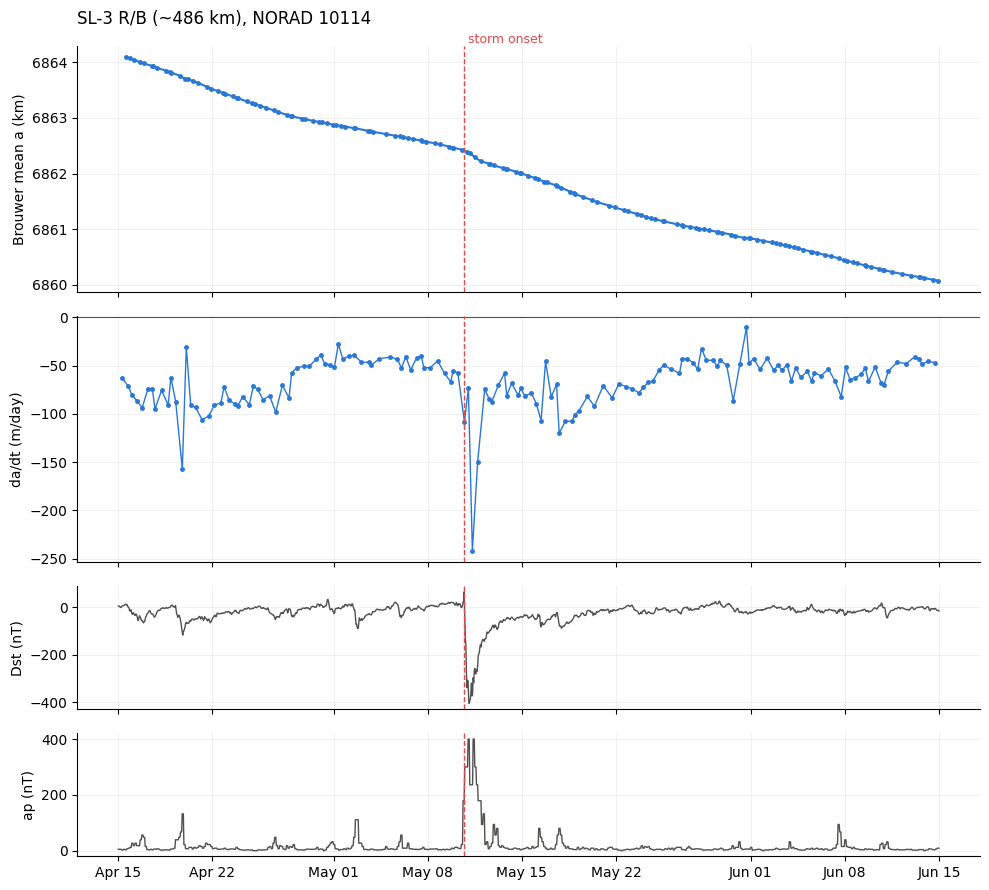

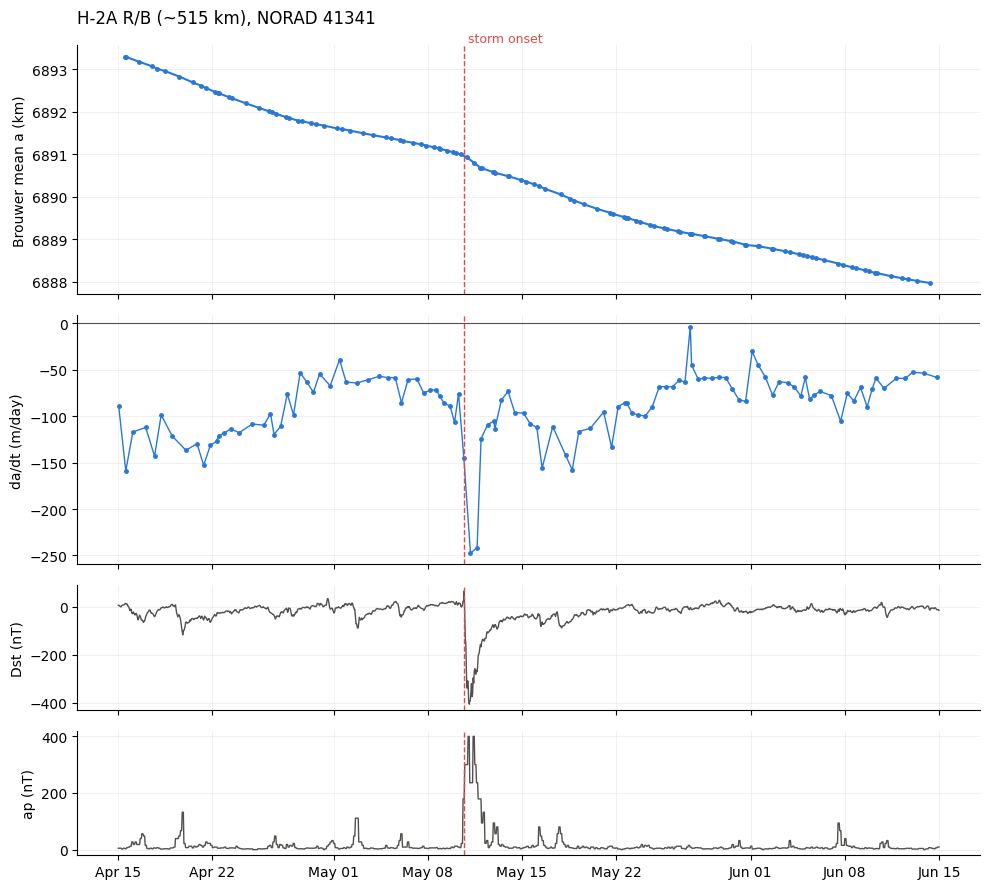

In [5]:
for norad_id, name in OBJECTS.items():
    plot_object_with_storm(f"{name}, NORAD {norad_id}",
                           tles[tles.norad_id == norad_id], rates[rates.norad_id == norad_id],
                           omni, STORM_ONSET, *WINDOW,
                           out_path=RESULTS / f"sanity_{norad_id}.png")

## 4. Mean decay rate 7 days before vs 7 days after the onset

Time-weighted mean = total change in a / total time, using only intervals that lie entirely on one side
of the onset, so no interval crosses the storm. `se_change` is a rough standard error from the scatter of
interval rates (a lower bound, because consecutive TLE fits share tracking data).

In [6]:
ba = mean_decay_before_after(rates, STORM_ONSET, days=7)
ba.insert(1, "name", ba["norad_id"].map(OBJECTS))
# Show m/day, which is easier to read than km/day
table = ba.copy()
for c in ["before_km_per_day", "after_km_per_day", "change_km_per_day", "se_change"]:
    table[c.replace("km_per_day", "m_per_day").replace("se_change", "se_change_m_per_day")] = table.pop(c) * 1000
table = table[["norad_id", "name", "before_m_per_day", "after_m_per_day", "change_m_per_day",
               "se_change_m_per_day", "ratio_after_before", "n_before", "n_after"]]
table.to_csv(RESULTS / "sanity_before_after.csv", index=False)
table.round(3)

,norad_id,name,before_m_per_day,after_m_per_day,change_m_per_day,se_change_m_per_day,ratio_after_before,n_before,n_after
0,7646,"Starlette (~800-1,100 km)",-0.044,-0.181,-0.137,0.327,4.145,18,17
1,8820,"LAGEOS-1 (control, ~5,900 km)",-0.079,-0.085,-0.006,0.032,1.081,7,8
2,10114,SL-3 R/B (~486 km),-48.842,-90.494,-41.652,9.967,1.853,15,19
3,22824,Stella (~800 km),-0.261,-0.425,-0.164,0.256,1.630,16,17
4,41341,H-2A R/B (~515 km),-69.769,-128.225,-58.456,15.846,1.838,14,13


In [7]:
# Space weather in the same two windows: storm strength (ap) and the solar-UV confounder (F10.7)
win = pd.Timedelta(days=7)
before_w, after_w = omni.loc[STORM_ONSET - win:STORM_ONSET], omni.loc[STORM_ONSET:STORM_ONSET + win]
print(f"mean ap:    before {before_w.ap.mean():5.1f} nT   after {after_w.ap.mean():5.1f} nT")
print(f"mean F10.7: before {before_w.f107.mean():5.1f} sfu  after {after_w.f107.mean():5.1f} sfu")

mean ap:    before  11.2 nT   after  69.2 nT
mean F10.7: before 201.3 sfu  after 219.4 sfu


## 5. Summary

**LAGEOS-1 (control): about zero, as expected.** Its decay rate is -0.08 m/day before and -0.09 m/day after
(change -0.006 +/- 0.03 m/day). Its a(t) only wanders by about +/-1 m with no step at the storm. That +/-1 m
(~0.1 m/day) is also the **noise floor** of TLE-derived semi-major axis: the real drag decay of LAGEOS is
about 1 mm/day, far below what TLEs can resolve.

**Low rocket bodies: a clear, sharp extra drop right after the onset.** The two ~490-520 km rocket bodies
go from about -50 to -70 m/day to a peak of about -240 m/day within a day of the onset, then recover over
about a week. The 7-day mean rate is about 1.85x the week before for both (SL-3 R/B: -49 to -90 m/day;
H-2A R/B: -70 to -128 m/day). Both changes are 4 or more rough standard errors from zero.

**~800 km objects: too small to see with this method.** Stella and Starlette change by about 0.15 m/day.
That is within one standard error and the same size as the TLE noise floor. Stella shows one dip right after
the storm, but the 7-day mean is not distinguishable from zero.

**Things to watch before scaling up:**
- **Near-duplicate TLEs.** Space-Track re-issues some TLEs with epochs a few milliseconds apart. Exact-match
  duplicate removal missed them, which produced fake rates of up to 10^5 km/day. `drop_duplicate_epochs`
  now treats epochs less than 1 s apart as one epoch and keeps the latest published.
- **F10.7 confounding.** F10.7 rose from about 140 sfu (end of April) to about 230 sfu just before the storm.
  It averages 201 sfu before vs 219 sfu after. So part of the 1.85x ratio is solar UV, not the storm.
  The decay rate in mid-April (high F10.7, quiet ap) was also about as fast as after the storm.
  A naive before/after ratio is therefore not the causal storm effect; the NRLMSISE-00 residual is needed.
- **Starlette has e ~ 0.021**, above our e < 0.01 main-sample cut. It is fine as a check here but would be
  excluded from the main analysis.
- **The higher rocket body decays faster.** H-2A R/B (~515 km) decays faster than SL-3 R/B (~486 km),
  probably because of a different area-to-mass ratio (and inclination). This is a reason to include drag
  sensitivity in the vulnerability map.
- The single interval that crosses the onset is excluded from both means, as required.